Note: I didn't see a download link on the linked page for the Diamonds dataset, but I found a github repo with a file that matched the number of rows ("almost 54,000") and had all the same columns, so I'm fairly certain it's the same one. Google said it's a fairly common data science dataset and can be found in many places. CSV downloaded from here:

https://github.com/selva86/datasets/blob/master/diamonds.csv

In [8]:
"""
This is the code for Assignment 10. It preprocesses and
performs linear & logistic regression on the diamonds dataset.
"""
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from statsmodels.formula.api import ols
from statsmodels.graphics.mosaicplot import mosaic

diamonds_df = pd.read_csv("diamonds.csv")

# PREPROCESSING STEP 1: CLEAN UP NULL

# Checking for null values. There are none, so
# no need to clean up null values.

def null_checker (df: pd.DataFrame):
    """
    Checks for null values in a dataframe.
    
    Input: pandas datadrame (df)
    
    Returns: print statement showing total of null values
    """
    null_vals = df.isna().sum().sum()
    return f"Total null values: {null_vals}"

# However, after examining min values, there
# are some x/y/z values of 0. Since these are
# measured in mm, they shouldn't be 0, since
# diamonds are 3D objects.

def drop_zeroes (df: pd.DataFrame):
    """
    Drops rows where the x/y/z
    measurement is 0.
    
    Input: diamonds_df (df)
    
    Returns: df with aforementioned rows dropped.
    """
    
    df = df[df['x'] != 0]
    df = df[df['y'] != 0]
    df = df[df['z'] != 0]

    return df

diamonds_df = drop_zeroes(diamonds_df)

print(null_checker(diamonds_df))

# PREPROCESSING STEP 2: DATA CLEANING
# Note: this section does not remove outliers, since
# outliers in this dataset are likely to represent
# natural variation in diamond characteristics
# and market value.

def strip_whitespace (col: pd.Series):
    """
    This function strips whitespaces from a column to
    keep everything standardized in case there are
    any extra whitespaces from data being input.
    
    Input: column from diamonds_df
    
    Returns: column with stripped whitespaces
    """

    stripped = col.str.strip()

    return stripped

# Calling strip_whitespace for all columns, skipping over ones
# that would raise an AttributeError.

for column in diamonds_df:
    try:
        diamonds_df[column] = strip_whitespace(diamonds_df[column])
    except AttributeError:
        continue

# Checking for common missing placeholders, none found.
# I also used the "filter" feature to examine the dataset in
# excel to see the unique values for each column, and
# did not identify anything that appeared to be missing.

def missing_count (df: pd.DataFrame):
    """
    This function checks for common placeholders used
    for missing values.

    Input: pandas dataframe (df)

    Returns: Totals of each common placeholder found in dataframe
    """
    # Converts text to lowercase for consistency. Gen AI used to
    # determine how to do this for an entire df at once.
    lower_df = pd.DataFrame()
    str_cols = df.select_dtypes(include=['object', 'string']).columns
    lower_df[str_cols] = df[str_cols].apply(lambda col: col.str.lower())
    # Checks common placeholders for missing values
    question_mark = (lower_df == "?").sum().sum()
    missing = (lower_df == "missing").sum().sum()
    triple_dot = (lower_df == "...").sum().sum()
    na = (lower_df == "n/a").sum().sum()

    return f"?: {question_mark}, Missing: {missing}, Ellipsis: {triple_dot}, N/A: {na}"

print(missing_count(diamonds_df))

# PREPROCESSING STEP 3: ONE-HOT ENCODING

def onehot (df: pd.DataFrame, col: str):
    """
    This function performs one-hot encoding on categorical columns.

    input: the diamonds_df DataFrame (df) and the name of the column
    you wish to one-hot encode as a str (col).

    returns: dataframe with one-hot encoding.
    """
    hot = pd.get_dummies(df, columns=[col])

    return hot

# I decided to one-hot encode the cut column, since it has
# the fewest categories.
diamonds_df = onehot(diamonds_df, "cut")

# PREPROCESSING STEP 4: CONVERT CATEGORICAL TO NUMERICAL

def color_to_num (df: pd.DataFrame):
    """
    This converts the color column to numerical
    values, where 1 = best and 6 = worst.

    Input: diamonds_df dataframe (df)

    Returns: column of color categories
    converted to numbers.
    """
    color_map = {"D": 1, "E": 2, "F": 3, "G": 4,
                 "H": 5, "I": 6, "J": 6}
    
    return df["color"].map(color_map)

diamonds_df["color"] = color_to_num(diamonds_df)

def clarity_to_num (df: pd.DataFrame):
    """
    This converts the clarity column to numerical
    values, where 1 = best and 8 = worst.

    Input: diamonds_df dataframe (df)

    Returns: column of clarity categories
    converted to numbers.
    """
    clarity_map = {"IF": 1, "VVS1": 2, "VVS2": 3, "VS1": 4,
                   "VS2": 5, "SI1": 6, "SI2": 7, "I1": 8}
    
    return df["clarity"].map(clarity_map)

diamonds_df["clarity"] = clarity_to_num(diamonds_df)

# PREPROCESSING STEP 5: STANDARDIZATION / NORMALIZATION

# This step will be handled prior to regression.

# PREPROCESSING STEP 6: MULTICOLLINEARITY

def drop_col (df: pd.DataFrame, col: str):
    """
    This function will drop a column from a dataframe.
    
    Input: diamonds_df dataframe (df) and the name of the column to drop
    as a string (col).
    
    Returns: DataFrame with specified column dropped.
    """

    dropped = df.drop(columns=col)

    return dropped

# Dropping the x, y, and z columns.
# These are all used to calculate Depth and are
# heavily positively correlated with carat, since
# the dimensions can be used to determine weight.
diamonds_df = drop_col(diamonds_df, "x")
diamonds_df = drop_col(diamonds_df, "y")
diamonds_df = drop_col(diamonds_df, "z")

# I chose to leave the one-hot cut columns alone this time so
# that the heatmap would show if any particular cut is
# correlated with price or other factors, despite there
# technically being multicollinearity with any 4 columns
# being able to predict the 5th.

Total null values: 0
?: 0, Missing: 0, Ellipsis: 0, N/A: 0


<Axes: >

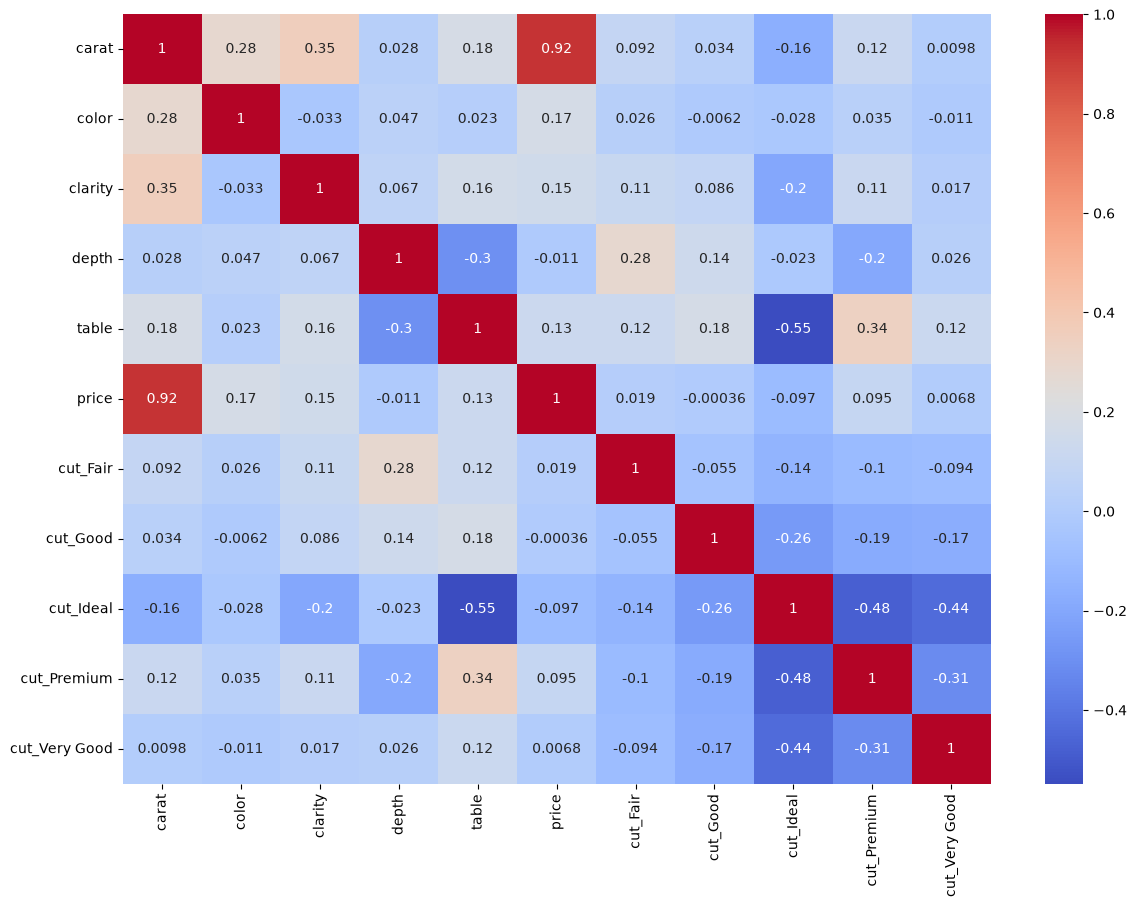

In [9]:
# Making a heatmap to examine correlation.
# Gen AI used to figure out how to make the heatmap bigger,
# since there are many variables to examine.
plt.figure(figsize=(14, 10))
sns.heatmap(diamonds_df.corr(), annot=True, cmap="coolwarm")

## Feature Selection

I want to use my regression models to predict price. Carat is by far the strongest correlated independent variable at 0.92. The next two most strongly correlated are color and clarity, at 0.17 and 0.15 respectively. They are not strong predictors, but they have the strongest correlation with price of any other variable besides carat, so they will be included to assist the linear regression model. These three independent variables are not very strongly correlated with each other* so this should not introduce any issues of collinearity.

*While they are not strongly correlated with each other, it should be noted that color and clarity are both more strongly correlated with carat than with price. In a genuine analysis this might be an indicator that it might not be worth using any variables besides carat for a model to predict price, but for the purposes of this assignment, I wanted to include multiple independent variables.

In [10]:
# LINEAR REGRESSION


def lin_reg_tts (df: pd.DataFrame, x1: str, x2: str, x3: str, y: str):
    """
    This function creates the X and y test and train data using
    train_test_split (hence the tts name).

    Input: diamonds_df (df), 3 column name strings as x variables
    (x1 - x3), and a column name string for y.

    Returns: values for X_train, X_ test, y_train, y_test
    """
    y = df[y]
    X = df[[x1, x2, x3]]

    return train_test_split(X, y, test_size=0.3, random_state=10)

X_train, X_test, y_train, y_test = lin_reg_tts(diamonds_df, "carat", "color", "clarity", "price")

def linear_reg (X_train: pd.DataFrame, X_test: pd.DataFrame, y_train: pd.Series, y_test: pd.Series):
    """
    This performs linear regression using the output
    of the lin_reg_tts function.

    Input: 4 output variables from lin_reg_tts

    Returns: Linear regression function,
    R-squared, MSE, and root MSE.
    """
    # Uses training data for fit
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    # Calculates MSE using test data
    mse = mean_squared_error(y_test, y_pred)

    # Calculating R-squared
    r_squared = lr.score(X_test, y_test)

    coef = lr.coef_
    return (
        f"Function: y = {coef[0]}*carat + {coef[1]}*color + {coef[2]}*clarity + {lr.intercept_}\n"
        f"R-Squared: {r_squared}\n"
        f"Mean-squared-error: {mse}\n"
        f"Root of MSE: {math.sqrt(mse)}"
    )

print(linear_reg(X_train, X_test, y_train, y_test))



Function: y = 8724.512810086422*carat + -322.4526537390144*color + -541.7666587267804*clarity + 793.7164372178981
R-Squared: 0.9014341700966786
Mean-squared-error: 1597645.1512280756
Root of MSE: 1263.9798856105565


## Linear Regression Model Performance

The linear regression model performed decently. The R-squared is about 90%, meaning that the model can explain 90% of the variance in price. This is good, but this model DOES include 3 independent variables (carat, color, and clarity), and we've learned in Akbani's class that adding more independent variables can sometimes inflate R-squared. So it's not terribly surprising that we're getting a high R-squared here.

The MSE seems quite high at 1.59 million, but taking the root of it (and thus putting it back into dollars) gives us about $1,263.98. Since the prices in the dataset range from a few hundred to nearly twenty thousand dollars, this isn't too bad for a basic linear regression model. But it's still high, so the model could use improvement.

It performed as well as it did mainly because of how highly correlated the carat variable is with price (0.92 according to the earlier heatmap). Heavier diamonds are more expensive, and this model takes weight into account. Adding in color and clarity make it a little more sophisticated as well.

This model could be improved in a few ways. For instance, we originally left in outliers to that the model could account for natural variance, but they can also heavily influence coefficients. Maybe outliers in the dataset are naturally occurring, or maybe there are some data points that should be removed - maybe some of the highest prices were driven by environmental factors outside the scope of this analysis (e.g., a rich person bought a low/mid-tier diamond for a lot of money just because they could). We could also consider adding in consideration for variable interaction, or try different preprocessing steps (e.g., see what happens if we keep in x/y/z and get rid of depth instead).

In [11]:
# I also wanted to see what Ordinary Least Squares (OLS)
# regression would look like here.

def ord_least_sq (df: pd.DataFrame, y: str, x1: str, x2: str, x3: str):
    """
    Runs OLS regression.

    Input: diamonds_df (df) and the y and x (x1-x3) column
    names used in the model as strings.
    """
    model = ols(f"{y} ~ {x1} + {x2} + {x3}",data=df).fit()
    return model.summary()

print(ord_least_sq(diamonds_df, "price", "carat", "color", "clarity"))



                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                 1.633e+05
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        17:02:07   Log-Likelihood:            -4.6125e+05
No. Observations:               53920   AIC:                         9.225e+05
Df Residuals:                   53916   BIC:                         9.225e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    784.6470     21.167     37.069      0.0

## OLS

The OLS y-intercept and coefficients seen above are nearly identical to the ones in the earlier linear regression function. From my understanding, the slight differences are because the linear regression function only used training data to build the model whereas OLS used the full dataset since there was no train/test split done there. Since the function and R-squared are nearly identical here, the earlier discussion of the first linear regression model's performance and potential for improvement also applies here.

In [12]:
# LOGISTIC REGRESSION

# First, I'll make an Expensive Y/N
# column to serve as the binary outcome
# to predict.

def expensive (df: pd.DataFrame, col1: str, col2: str):
    """
    This function adds a new column to a df consisting
    of boolean values dependent on whether the value
    of another column is at/above or below the median.

    Input: diamonds_df (df), column to base new column
    off of (col1), and name for the new boolean
    column (col2).

    Returns: dataframe with new column added
    """
    # Gen AI used to learn how to use the truthiness
    # of the >= statement to make a boolean column.
    median = df[col1].median()
    df[col2] = df[col1] >= median
    # Drops col1 (price) so it's not using the price
    # to predict if it's expensive.
    df = df.drop(columns=col1)

    return df

diamonds_logistic_df = expensive(diamonds_df, "price", "expensive")

def logistic_prep (df: pd.DataFrame, outcome: str):
    """
    This function performs the train test split in
    preparation of logistic regression.

    Input: diamonds_logistic_df (df), name of column
    of outcomes to predict as string (outcome)

    Returns: train test split
    """
    # X data in this is everything but the Expensive
    # column. I wanted to compare the results of
    # using all the independent variables here vs
    # the feature selection of the linear model.
    X = df.drop(outcome, axis=1)
    y = df[outcome]

    return train_test_split(X, y, test_size=0.2,
                            random_state=10, stratify=y)

X_train, X_test, y_train, y_test = logistic_prep(diamonds_logistic_df, "expensive")

def standardize (train, test):
    """
    Standardizes the train/test data using standard scaler.

    Input: X_train (train) and X_test (test) data.

    Returns: standardized arrays of the X_train and X_test
    values.
    """
    scaler = StandardScaler()
    training = scaler.fit_transform(train)
    testing = scaler.fit_transform(test)

    return training, testing

X_train, X_test = standardize(X_train, X_test)

def log_regression (train_x, train_y, test_x):
    """
    Performs logistic regression on the training data.

    Input: X and y training data (train_x, train_y),
    X testing data (test_x).

    Returns: predictions of X testing data.
    """
    regression = LogisticRegression(random_state=10)
    regression.fit(train_x, train_y)

    return regression.predict(test_x)

y_pred = log_regression(X_train, y_train, X_test)

def accuracy_and_recall (test_y, pred_y):
    """
    Calculates accuracy and recall scores.

    Input: y test and prediction data (test_y,
    pred_y)

    Returns: accuracy and recall scores
    """
    ac = accuracy_score(test_y, pred_y)
    rc = recall_score(test_y, pred_y)

    return ac, rc

# Calls the accuracy/recall function and prints the results
accuracy, recall = accuracy_and_recall(y_test, y_pred)
print(f"Accuracy: {accuracy}\nRecall: {recall}")



Accuracy: 0.9745919881305638
Recall: 0.9688485073243093


(<Figure size 640x480 with 3 Axes>, {('0', '0'): (0.0, np.float64(0.0), 0.49742016918375487, np.float64(0.9770806641560222)), ('0', '1'): (0.0, np.float64(0.9804029232922349), 0.49742016918375487, np.float64(0.019597076707765008)), ('1', '0'): (0.5023952935618643, np.float64(0.0), 0.49760470643813576, np.float64(0.031047999344542235)), ('1', '1'): (0.5023952935618643, np.float64(0.03437025848075485), 0.49760470643813576, np.float64(0.9656297415192451))})


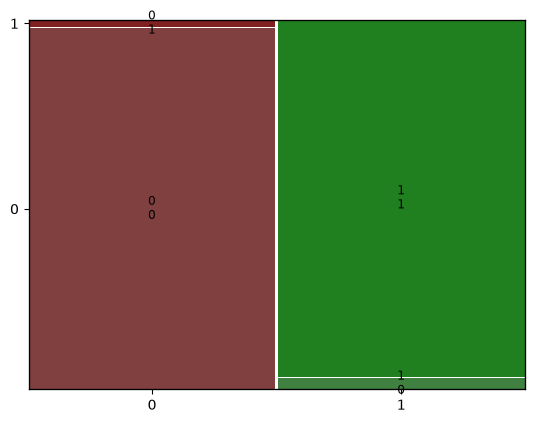

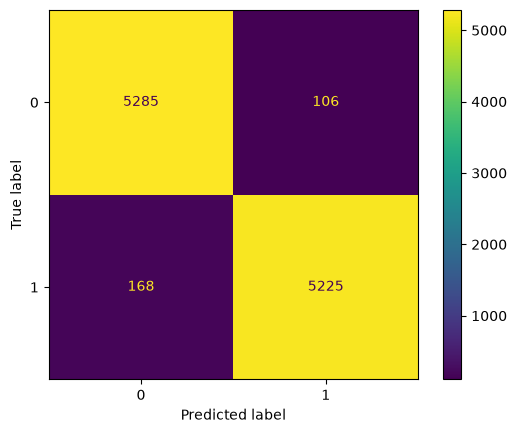

In [13]:
# Confusion mosaic and Confusion matrix display
# Since these are already their own functions,
# it seemed redundant to make new functions just
# to display these.

cm = confusion_matrix(y_test, y_pred)
print(mosaic(cm))
ConfusionMatrixDisplay(confusion_matrix=cm).plot()

In [14]:
# I added this function from the class notes just
# to see what the precision and recall scores were.
# I removed the "elif" and "else" based on the
# linter's suggestions.

def precision_and_recall(calc_type:str, tp:int, fp:int, fn:int):
    """
    This function produces prection and recall results 
    based on what is passed.

    Input: type of calculation (precision or recall), true
    positives, false positives, false negatives.

    Returns: result of requested calculation
    """
    if calc_type == "precision":
        return tp / (tp + fp) if (tp + fp) > 0 else 0
    if calc_type == "recall":
        return tp / (tp + fn) if (tp + fn) > 0 else 0
    raise ValueError("calc_type must be 'precision' or 'recall'")

# Calls function for precision and recall. Note that recall score
# is the same as above.
print(f"Precision score: {precision_and_recall("precision",
                                               5225, 106, 168)}")
print(f"Recall score: {precision_and_recall("recall",
                                            5225, 106, 168)}")

Precision score: 0.9801163008816357
Recall score: 0.9688485073243093


## How do you prepare the same dataset for linear and logistic regression?

After preprocessing is complete, preparing the dataset for linear vs logistic regression diverges. For linear regression, you want to perform feature selection before making the model, so you can make a heatmap of the different variables to see what's strongly correlated, where collinearities might lie, et cetera. From there, you can choose the independent variables most strongly correlated with your dependent variable (while ensuring the independent variables aren't too strongly correlated with each other. Generally, correlations above 0.5 are probably too strong since it's above chance, but this really depends on the dataset). IMPORTANT: for linear regression, your dependent variable (what you're predicting) should be a continuous variable. In this case, it was price.

For logistic regression, you split the data into X and y values (y is the dependent variable, X is everything else), then you split each into training data and testing data, then use scaling to standardize the X train and test values. IMPORTANT: for logistic regression, your dependent variable should be boolean, i.e. True/False, Yes/No, Heads/Tails, et cetera. After this, you use training data to develop your model, then test it with the testing data. This helps to make sure your model doesn't overfit to the data by testing it on stuff it hasn't seen before.

## Logistic Regression Model Performance

This model performed well (or so it seems - see below paragraph). The accuracy score was 97.5%, recall was 96.9%, and precision was 98.0%. In this case, I would say that accuracy is the more important score. I based the dependent variable (Expensive) values on whether the price was above or below the median price in the dataset, so the split was 50/50, meaning the results wouldn't be skewed in favor of false positives or false negatives (e.g., if 99% of the values were True and the model guessed True every time, it would be 99% accurate, but that would be misleading). I imagine the use case of this would be a jeweler wanting to know which diamonds that come through their store are worth trying to sell at a high price, so overlooking a good diamond (false negative) or trying to push a bad diamong (false positive) wouldn't be terrible so long as enough predictions were correct over time to generate profits.

This model performed well because of a large, balanced dataset. More data means more opportunities to see patterns and a balanced dependent variable means the model isn't rewarded for just guessing the same thing every time. However, the high scores noted above COULD indicate overfitting. I did the train/test/split to try to spot overfitting, so the model didn't INSANELY overfit to the training data, but since I included all available independent variables in the logistic model it might still be seeing patterns in noise.

In order to improve it, you could do a few things. You could perform more focused feature selection like I did in the linear regression example to see if cutting down independent variales could improve results on the test data. The standardization approach I took was naive, so you could take a more careful approach, like standardizing continuous features one way while handling the boolean columns separately. To make the results more applicable to real-world scenarios, it might be worth searching for more data and talking to real diamond dealers to determine what really is "expensive" instead of just taking the median price as the line. You could also add more rows to the dataset to give the model more to work with.

## Linting

See below for the 85.1% linting score. The linter did not like the train/test/split variables names, but since it was said these are standard during class, I kept them in.

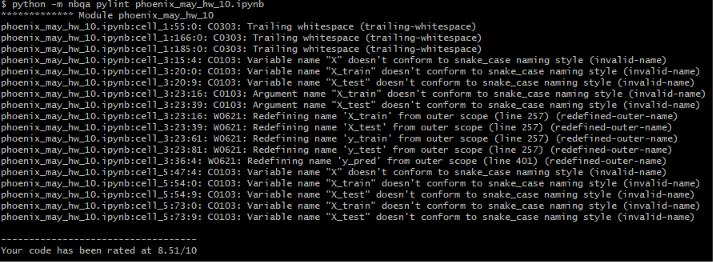